# 04. Ninguém vence sozinho: o stacking

**Ideia.** Em vez de escolher um modelo, treinamos vários de famílias diferentes e um **meta-modelo**
(Regressão Logística) aprende quanto confiar em cada um. Funciona se os modelos **erram em e-mails diferentes**.

**Protocolo (experimento 02).** Base de teste trancada com 20%; nos 80% restantes, validação cruzada 3 × 5 por
grupo; dentro de cada treino, outra CV por grupo gera as notas *out-of-fold* que alimentam o meta-modelo (assim
ele nunca vê a nota de um modelo sobre um e-mail que esse modelo usou para treinar).

**Stacking 7:** um representante por família: linear (Reg. Logística), kernel (SVM RBF), vizinhos (kNN),
rede neural (MLP), probabilística (Naive Bayes), *bagging* (Extra Trees) e *boosting* (LightGBM).

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/notebooks/04_stacking.ipynb)

**No Google Colab:** rode tudo (*Ambiente de execução → Executar tudo*). Na primeira vez, a célula abaixo baixa o
projeto, instala os pacotes e **reinicia o ambiente**; quando o Colab reconectar, use *Executar tudo* de novo.
No computador, ela não faz nada (siga o [INSTALACAO.md](https://github.com/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/INSTALACAO.md)).

In [1]:
# Google Colab: prepara o ambiente na primeira execução. No computador, esta célula não faz nada.
import os, subprocess, sys
if "google.colab" in sys.modules:
    PROJETO = "/content/filtro-spam-stacking-enron"
    if not os.path.isdir(PROJETO):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/felipe44776-eseg/filtro-spam-stacking-enron.git", PROJETO], check=True)
    os.chdir(PROJETO)
    sys.path.insert(0, PROJETO)
    MARCA = "/content/.spamfilter_instalado"
    if not os.path.exists(MARCA):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
        open(MARCA, "w").close()
        print("Pacotes instalados. O Colab vai reiniciar o ambiente: quando reconectar, use Executar tudo de novo.")
        os.kill(os.getpid(), 9)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spamfilter import caminhos, estatistica, graficos, metricas, modelos, saidas
from spamfilter.dados import carregar
from spamfilter.motor import Motor

H = caminhos.EXPERIMENTOS / "02_stacking"
R = pd.read_csv(H / "stacking_cv.csv", sep=";", decimal=",")
resumo = (R.groupby(["metodo", "tipo"]).agg(mcc=("mcc", "mean"), mcc_dp=("mcc", "std"), pr_auc=("pr_auc", "mean"),
                                            real_lixeira=("real_lixeira", "mean"), spam_passou=("spam_passou", "mean"), treino_s=("treino_s", "mean"))
          .sort_values("mcc", ascending=False).reset_index(level="tipo"))
mostra = resumo.copy(); mostra[["real_lixeira", "spam_passou"]] *= 100
print(mostra.round(4).to_string())

                                    tipo     mcc  mcc_dp  pr_auc  real_lixeira  spam_passou  treino_s
metodo                                                                                               
Stacking 7 (1 por família)    combinação  0.9748  0.0106  0.9973        0.8058       1.6111   42.3128
Stacking 13 (todos)           combinação  0.9740  0.0098  0.9973        0.8398       1.6389   65.5643
Stacking 13 + L1              combinação  0.9731  0.0102  0.9972        0.8852       1.6667   65.5643
Média 13 (votação)            combinação  0.9687  0.0094  0.9971        1.1917       1.5556   65.5643
Stacking 4 (LR+NB+RF+LGBM)    combinação  0.9659  0.0098  0.9959        1.2144       1.8889   21.3265
Caruana 13                    combinação  0.9649  0.0104  0.9963        1.1803       2.1111   65.5643
LinearSVC                   modelo único  0.9595  0.0127  0.9953        1.8272       1.3889    0.0437
MLP (rede neural)           modelo único  0.9586  0.0145  0.9948        1.4866    

## 1. Mais modelos não é melhor
Com 13 modelos, o stacking empata com o de 7; a seleção gulosa de Caruana e a votação simples ficam atrás.
O que importa é a **diversidade**, não a quantidade.

In [3]:
P15 = R.pivot_table(index=["seed", "fold"], columns="metodo", values="mcc")
pares = [("Stacking 7 (1 por família)", o) for o in ["Stacking 13 (todos)", "Stacking 13 + L1", "Caruana 13", "Média 13 (votação)",
                                                     "Stacking 4 (LR+NB+RF+LGBM)", "LinearSVC"]]
C15 = estatistica.comparar(P15, pares, R.n_tr.mean(), R.n_te.mean(), runs=3)
print(C15[["A", "B", "dif", "p_holm", "P_A_melhor", "P_equivalentes", "P_B_melhor"]].round(3).to_string(index=False))

                         A                          B   dif  p_holm  P_A_melhor  P_equivalentes  P_B_melhor
Stacking 7 (1 por família) Stacking 4 (LR+NB+RF+LGBM) 0.009   0.144       0.377           0.623       0.000
Stacking 7 (1 por família)                 Caruana 13 0.010   0.144       0.488           0.512       0.000
Stacking 7 (1 por família)                  LinearSVC 0.015   0.172       0.774           0.224       0.001
Stacking 7 (1 por família)         Média 13 (votação) 0.006   0.370       0.155           0.845       0.000
Stacking 7 (1 por família)           Stacking 13 + L1 0.002   1.000       0.006           0.994       0.000
Stacking 7 (1 por família)        Stacking 13 (todos) 0.001   1.000       0.001           0.999       0.000


## 2. Quem erra o quê (20 folds de confirmação, experimento 03)
Para cada par de modelos: dos e-mails que pelo menos um dos dois errou, que fração os dois erraram juntos
(índice de Jaccard). Valores baixos = erros diferentes = o time se completa.

e-mails de teste (20 folds): 16548 | erros do Stacking 7: 182 | e-mails em que a maioria dos 7 erra: 263
                erros  só ele erra  acerta quando a maioria (≥4) erra
Reg. Logística    316           11                                 31
SVM RBF           318           17                                 31
kNN cosseno       519          194                                 95
MLP               301           17                                 61
Naive Bayes       932          470                                 50
Extra Trees       341           61                                 94
LightGBM          402           98                                 97


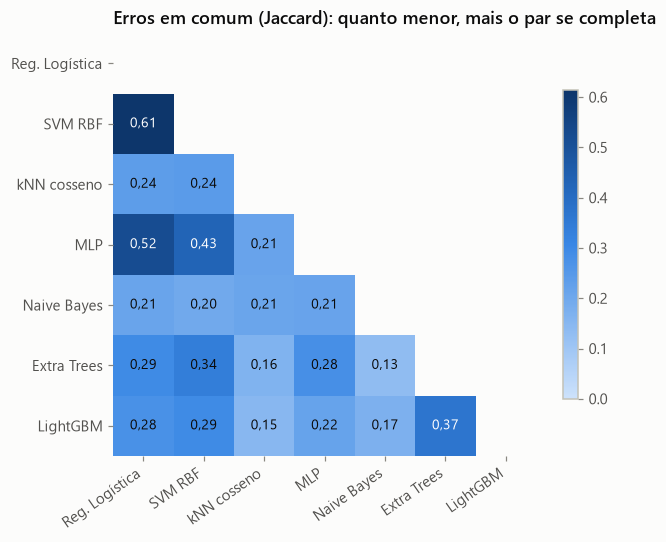

In [4]:
base = carregar()
m = Motor(base, log=lambda *a: None)
CONF = m.adicionar_divisoes([201, 202, 203, 204])
P = modelos.STACKING7_PADRAO
LIMIAR0 = {f: (0.0 if f == "SVM RBF" else 0.5) for f in modelos.FAMILIAS}      # SVC sem probabilidade: distância à fronteira
erros, ys = {f: [] for f in modelos.FAMILIAS}, []
for c in CONF:
    yte = m.y_teste(c); ys.append(yte)
    for i, f in enumerate(modelos.FAMILIAS):
        erros[f].append((m.carregar(c, f, P[i])[1] > LIMIAR0[f]).astype(int) != yte)
    _, yh, _ = m.prever_stacking(P, c); erros.setdefault("Stacking 7", []).append(yh != np.concatenate([yte])[: len(yh)])
E = pd.DataFrame({f: np.concatenate(v) for f, v in erros.items()})
fams = modelos.FAMILIAS
J = pd.DataFrame([[(E[a] & E[b]).sum() / max((E[a] | E[b]).sum(), 1) for b in fams] for a in fams], index=fams, columns=fams)
so_ele = pd.Series({f: int((E[f] & ~E[[o for o in fams if o != f]].any(axis=1)).sum()) for f in fams})
maioria_erra = E[fams].sum(axis=1) >= 4
resgate = pd.Series({f: int((~E[f] & maioria_erra).sum()) for f in fams})
tab_erros = pd.DataFrame({"erros": E[fams].sum(), "só ele erra": so_ele, "acerta quando a maioria (≥4) erra": resgate})
print(f"e-mails de teste (20 folds): {len(E)} | erros do Stacking 7: {int(E['Stacking 7'].sum())} | "
      f"e-mails em que a maioria dos 7 erra: {int(maioria_erra.sum())}")
print(tab_erros.to_string())

fig, ax = plt.subplots(figsize=(6.2, 5.2))
mask = np.triu(np.ones_like(J, dtype=bool), k=0)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", graficos.SEQUENCIAL)
Jm = np.ma.masked_where(mask, J.values)
im = ax.imshow(Jm, cmap=cmap, vmin=0, vmax=max(0.6, float(J.values[~mask].max())))
for a in range(len(fams)):
    for b in range(a):
        v = J.values[a, b]
        ax.text(b, a, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=9,
                color="white" if v > 0.35 else graficos.TINTA)
ax.set_xticks(range(len(fams)), fams, rotation=35, ha="right"); ax.set_yticks(range(len(fams)), fams)
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("Erros em comum (Jaccard): quanto menor, mais o par se completa")
fig.colorbar(im, ax=ax, shrink=0.7)
graficos.mostrar(fig, "04_erros_em_comum")

## 3. Quanto o meta-modelo confia em cada um
Pesos da Regressão Logística do meta-modelo sobre as notas padronizadas (média dos 20 folds).

Naive Bayes       0.03
MLP               0.67
LightGBM          0.74
Reg. Logística    0.78
SVM RBF           1.09
Extra Trees       1.36
kNN cosseno       1.67


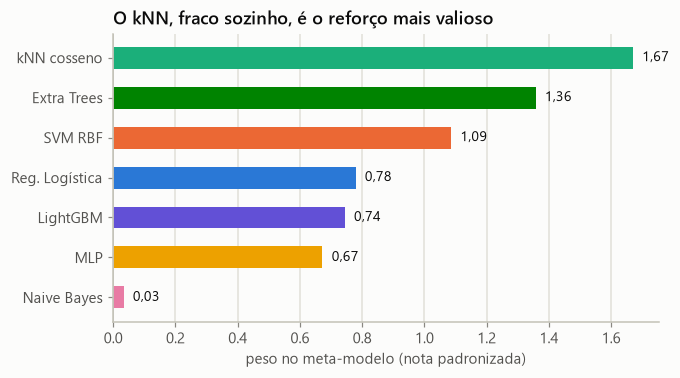

In [5]:
W = pd.DataFrame([m.pesos_meta(P, c) for c in CONF])
pesos = W[fams].mean().sort_values()
print(pesos.round(2).to_string())
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.barh(range(len(pesos)), pesos.values, height=0.55,
        color=[graficos.FAMILIA_COR[graficos.FAMILIA_DO_MEMBRO[f]] for f in pesos.index])
for i, v in enumerate(pesos.values):
    ax.text(v + (0.03 if v >= 0 else -0.03), i, f"{v:.2f}".replace(".", ","), va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_yticks(range(len(pesos)), pesos.index); ax.axvline(0, color=graficos.EIXO, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("peso no meta-modelo (nota padronizada)"); ax.set_title("O kNN, fraco sozinho, é o reforço mais valioso")
graficos.mostrar(fig, "04_pesos_meta")

## 4. Stacking 7 × melhor modelo único (20 folds de confirmação)

In [6]:
linhas = []
for c in CONF:
    yte = m.y_teste(c)
    linhas.append(dict(split=c, metodo="Stacking 7", **metricas.metricas(yte, *m.prever_stacking(P, c))))
    linhas.append(dict(split=c, metodo="LinearSVC", **metricas.metricas(yte, *m.prever_linearsvc(modelos.LINEARSVC_PADRAO, c))))
    for i, f in enumerate(fams):
        s = m.carregar(c, f, P[i])[1]; yh = (s > LIMIAR0[f]).astype(int)
        linhas.append(dict(split=c, metodo=f, **metricas.metricas(yte, s, yh, yh)))
R20 = pd.DataFrame(linhas)
por_metodo = R20.groupby("metodo")[["mcc", "pr_auc", "real_lixeira", "spam_passou"]].mean().sort_values("mcc", ascending=False)
print(por_metodo.round(4).to_string())
P20 = R20.pivot(index="split", columns="metodo", values="mcc")
C20 = estatistica.comparar(P20, [("Stacking 7", "LinearSVC")], 3310, 828, runs=4)
print(C20[["A", "B", "dif", "p", "P_A_melhor", "P_equivalentes", "P_B_melhor"]].round(4).to_string(index=False))

                   mcc  pr_auc  real_lixeira  spam_passou
metodo                                                   
Stacking 7      0.9734  0.9973        0.0091       0.0156
LinearSVC       0.9600  0.9952        0.0174       0.0150
MLP             0.9560  0.9941        0.0150       0.0260
Reg. Logística  0.9546  0.9949        0.0213       0.0138
SVM RBF         0.9543  0.9951        0.0220       0.0125
Extra Trees     0.9505  0.9922        0.0193       0.0238
LightGBM        0.9420  0.9929        0.0244       0.0240
kNN cosseno     0.9267  0.9767        0.0365       0.0188
Naive Bayes     0.8688  0.8888        0.0584       0.0512
         A         B    dif      p  P_A_melhor  P_equivalentes  P_B_melhor
Stacking 7 LinearSVC 0.0134 0.0006      0.8446          0.1554         0.0


**Leitura.** O kNN é dos mais fracos sozinho, mas é o que menos erra junto com os outros, e o meta-modelo
percebe isso: dá a ele um dos maiores pesos. É a definição prática de diversidade. Por isso o Stacking 7 é o
candidato: modelos distintos que erram de formas distintas.

In [7]:
ext = pd.read_csv(H / "stacking_externo.csv", sep=";", decimal=",").groupby("modelo")[["mcc", "pr_auc", "real_lixeira", "spam_passou"]].mean()
saidas.gravar("04_stacking", {
    "stacking": dict(variantes=resumo.reset_index().rename(columns={"metodo": "nome"}), comparacoes_15_folds=C15,
                     erros_em_comum=dict(modelos=fams, matriz=J.values.round(4)), tabela_erros=tab_erros.reset_index().rename(columns={"index": "familia"}),
                     pesos_meta=pesos.to_dict(), confirmacao_20_folds=por_metodo.reset_index(), comparacao=C20,
                     externo_exp02=ext.reset_index()),
}, fonte="scripts/04_stacking.py")
print("gravado: resultados/04_stacking.json")

gravado: resultados/04_stacking.json
